In [38]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
import math
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, Subset, ConcatDataset
from torchvision import datasets, transforms
from IPython.display import clear_output

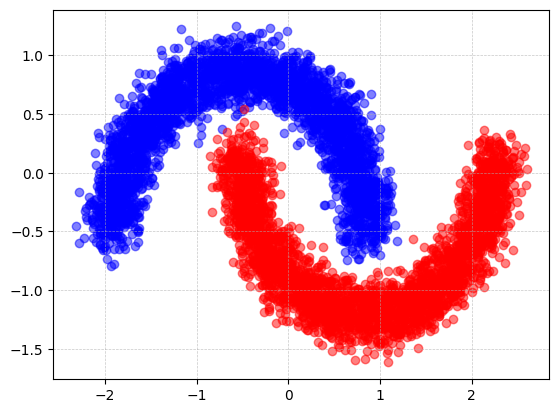

In [39]:
x, y = make_moons(n_samples=100000, noise=0.1)
x = (x - x.mean()) / x.std()

plt.scatter(x[:,0][y == 0][:3000], x[:,1][y == 0][:3000], alpha=0.5, color="blue")
plt.scatter(x[:,0][y == 1][:3000], x[:,1][y == 1][:3000], alpha=0.5, color="red")
plt.grid(
    True,
    linestyle='--',
    linewidth=0.5,
    alpha=0.7
)

In [40]:
X = torch.tensor(x, dtype=torch.float32)
diffusion_steps = 40
s = 0.008
timesteps = torch.tensor(range(0, diffusion_steps), dtype=torch.float32)
schedule = torch.cos((timesteps / diffusion_steps + s) / (1 + s) * torch.pi / 2)**2

baralphas = schedule / schedule[0]
betas = 1 - baralphas / torch.concatenate([baralphas[0:1], baralphas[0:-1]])
alphas = 1 - betas


In [41]:
class DiffusionBlock(nn.Module):
    def __init__(self, nunits):
        super(DiffusionBlock, self).__init__()
        self.linear = nn.Linear(nunits, nunits)
        
    def forward(self, x: torch.Tensor):
        x = self.linear(x)
        x = nn.functional.relu(x)
        return x
        
class DiffusionModel(nn.Module):
    def __init__(self, nfeatures: int, nblocks: int = 2, nunits: int = 64):
        super(DiffusionModel, self).__init__()
        
        self.inblock = nn.Linear(nfeatures+1, nunits)
        self.midblocks = nn.ModuleList([DiffusionBlock(nunits) for _ in range(nblocks)])
        self.outblock = nn.Linear(nunits, nfeatures)

    def forward(self, x: torch.Tensor, t: torch.Tensor) -> torch.Tensor:
        val = torch.hstack([x, t])  # Add t to inputs
        val = self.inblock(val)
        for midblock in self.midblocks:
            val = midblock(val)
        val = self.outblock(val)
        return val

def rbf_kernel(X, Y, sigma=1.0):
    XX = (X**2).sum(dim=1, keepdim=True)
    YY = (Y**2).sum(dim=1, keepdim=True)
    dist = XX - 2 * X @ Y.T + YY.T
    return torch.exp(-dist / (2 * sigma**2))

def mmd(X, Y, sigma=1.0):
    Kxx = rbf_kernel(X, X, sigma)
    Kyy = rbf_kernel(Y, Y, sigma)
    Kxy = rbf_kernel(X, Y, sigma)
    return Kxx.mean() + Kyy.mean() - 2 * Kxy.mean()

def pairwise_distances(X, Y):
    XX = (X**2).sum(dim=1, keepdim=True)
    YY = (Y**2).sum(dim=1, keepdim=True)
    return XX - 2 * X @ Y.T + YY.T

def knn_fraction_coverage(X, Y, k=1, threshold=0.1):
    dist2 = pairwise_distances(X, Y)
    knn_dist = dist2.topk(k, largest=False, dim=1).values.sqrt()
    covered = (knn_dist.mean(dim=1) <= threshold).float()
    return covered.mean()

def knn_fraction_coverage_both(X, Y, k=1, threshold=0.1):
    cov_xy = knn_fraction_coverage(X, Y, k, threshold)
    cov_yx = knn_fraction_coverage(Y, X, k, threshold)
    return cov_xy, cov_yx

In [42]:
def noise(Xbatch, t):
    eps = torch.randn(size=Xbatch.shape)
    noised = (baralphas[t] ** 0.5).repeat(1, Xbatch.shape[1]) * Xbatch + ((1 - baralphas[t]) ** 0.5).repeat(1, Xbatch.shape[1]) * eps
    return noised, eps

noiselevel = 20
noised, eps = noise(X, torch.full([len(X), 1], fill_value=noiselevel))
denoised = 1 / torch.sqrt(baralphas[noiselevel]) * (noised - torch.sqrt(1 - baralphas[noiselevel]) * eps)

model = DiffusionModel(nfeatures=2, nblocks=2)
device = "cuda"
model = model.to(device)

nepochs = 100
batch_size = 2048


loss_fn = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)
scheduler = optim.lr_scheduler.LinearLR(optimizer, start_factor=1.0, end_factor=0.01, total_iters=nepochs)

print(sum(p.numel() for p in model.parameters()))

8706


In [44]:
import torch
import torch.nn as nn
from sklearn.datasets import make_moons

model1 = MLP().cuda()

x, y = make_moons(n_samples=100000, noise=0.1)
x = (x - x.mean()) / x.std()

x = torch.tensor(x, dtype=torch.float32)
y = torch.tensor(y, dtype=torch.float32).unsqueeze(1)

optimizer = torch.optim.Adam(model1.parameters(), lr=1e-3)
criterion = nn.BCEWithLogitsLoss()

batch_size = 256
epochs = 50

for epoch in range(epochs):
    perm = torch.randperm(len(x))
    
    for i in range(0, len(x), batch_size):
        idx = perm[i:i+batch_size]
        
        t = torch.randint(0, diffusion_steps, (len(x[idx]), 1)).long()
        xb, _ = noise(x[idx], t)
        
        yb = y[idx]
        tb = t.float() / diffusion_steps

        optimizer.zero_grad()
        
        logits = model1(xb.cuda(), tb.cuda())
        loss = criterion(logits, yb.cuda())
        
        loss.backward()
        optimizer.step()
    
    print(f"epoch {epoch+1} loss {loss.item():.4f}")


epoch 1 loss 0.4733
epoch 2 loss 0.5057
epoch 3 loss 0.4630
epoch 4 loss 0.4500
epoch 5 loss 0.4844
epoch 6 loss 0.3874
epoch 7 loss 0.4395
epoch 8 loss 0.3913
epoch 9 loss 0.4325
epoch 10 loss 0.4900
epoch 11 loss 0.4217
epoch 12 loss 0.4106
epoch 13 loss 0.4343
epoch 14 loss 0.3572
epoch 15 loss 0.5021
epoch 16 loss 0.3897
epoch 17 loss 0.4861
epoch 18 loss 0.3943
epoch 19 loss 0.3914
epoch 20 loss 0.4200
epoch 21 loss 0.4630
epoch 22 loss 0.4223
epoch 23 loss 0.4688
epoch 24 loss 0.3721
epoch 25 loss 0.4831
epoch 26 loss 0.3648
epoch 27 loss 0.4376


KeyboardInterrupt: 

In [29]:
model
model.load_state_dict(torch.load('model.pt'))

<All keys matched successfully>

In [30]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(3, 16)
        self.fc2 = nn.Linear(16, 16)
        self.fc3 = nn.Linear(16, 1)

    def forward(self, x, t):

        if t.dim() == 1:
            t = t.unsqueeze(1)

        x = torch.cat([x, t], dim=1)
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = self.fc3(x)
        return x

In [31]:
import torch
import torch.nn as nn
from sklearn.datasets import make_moons

model1 = MLP().cuda()

x, y = make_moons(n_samples=100000, noise=0.1)
x = (x - x.mean()) / x.std()

x = torch.tensor(x, dtype=torch.float32)
y = torch.tensor(y, dtype=torch.float32).unsqueeze(1)

optimizer = torch.optim.Adam(model1.parameters(), lr=1e-3)
criterion = nn.BCEWithLogitsLoss()

batch_size = 256
epochs = 50

for epoch in range(epochs):
    perm = torch.randperm(len(x))
    
    for i in range(0, len(x), batch_size):
        idx = perm[i:i+batch_size]
        
        t = torch.randint(0, diffusion_steps, (len(x[idx]), 1)).long()
        xb, _ = noise(x[idx], t)
        
        yb = y[idx]
        tb = t.float() / diffusion_steps

        optimizer.zero_grad()
        
        logits = model1(xb.cuda(), tb.cuda())
        loss = criterion(logits, yb.cuda())
        
        loss.backward()
        optimizer.step()
    
    print(f"epoch {epoch+1} loss {loss.item():.4f}")


epoch 1 loss 0.5690
epoch 2 loss 0.4519
epoch 3 loss 0.4519
epoch 4 loss 0.4298


KeyboardInterrupt: 

In [32]:
# torch.save(model1.state_dict(), "model1.pt")
model1.load_state_dict(torch.load('model1.pt'))

<All keys matched successfully>

In [33]:
nfeatures, nsamples = 2, 5000
s = 3
xt_hist = []
xt = torch.randn(size=(nsamples, nfeatures)).to(device)
xt_hist.append(xt.cpu())

for t in range(diffusion_steps-1, 0, -1):
    with torch.no_grad():
        predicted_noise = model(xt, torch.full([nsamples, 1], t).to(device))
            
    dre_xt = xt.detach().clone().requires_grad_(True)
    t_batch = torch.full((xt.shape[0], 1), t, device=device)

    
    logits = model1(dre_xt, t_batch / diffusion_steps)
    log_probs = F.logsigmoid(logits)
        
    guide_score = torch.autograd.grad(
        outputs=log_probs.sum(),
        inputs=dre_xt
    )[0]

    xt = 1 / (alphas[t] ** 0.5) * (xt - (1 - alphas[t]) / ((1 - baralphas[t]) ** 0.5) * predicted_noise)
    xt = xt + s * betas[t] * guide_score

    if t == int(diffusion_steps/4) or t == int(diffusion_steps/2) or t == int(3*diffusion_steps/4):
        xt_hist.append(xt.cpu())

    if t > 1:
        variance = betas[t]
        std = variance ** 0.5
        xt += std * torch.randn(size=(nsamples, nfeatures)).to(device)

xt_hist.append(xt.cpu())
xt = xt.cpu()

In [34]:
nfeatures, nsamples = 2, 5000
s = 3
xt_hist1 = []
xt = torch.randn(size=(nsamples, nfeatures)).to(device)
xt_hist1.append(xt.cpu())

for t in range(diffusion_steps-1, 0, -1):
    with torch.no_grad():
        predicted_noise = model(xt, torch.full([nsamples, 1], t).to(device))
            
    dre_xt = xt.detach().clone().requires_grad_(True)
    t_batch = torch.full((xt.shape[0], 1), t, device=device)

    
    logits = model1(dre_xt, t_batch / diffusion_steps)
    log_probs = F.logsigmoid(logits)
        
    guide_score = torch.autograd.grad(
        outputs=log_probs.sum(),
        inputs=dre_xt
    )[0]

    xt = 1 / (alphas[t] ** 0.5) * (xt - (1 - alphas[t]) / ((1 - baralphas[t]) ** 0.5) * predicted_noise)
    xt = xt + 1 * s * betas[t] * guide_score

    if t == int(diffusion_steps/4) or t == int(diffusion_steps/2) or t == int(3*diffusion_steps/4):
        xt_hist1.append(xt.cpu())

    if t > 1:
        variance = betas[t]
        std = variance ** 0.5
        xt += std * torch.randn(size=(nsamples, nfeatures)).to(device)

xt_hist1.append(xt.cpu())
xt = xt.cpu()

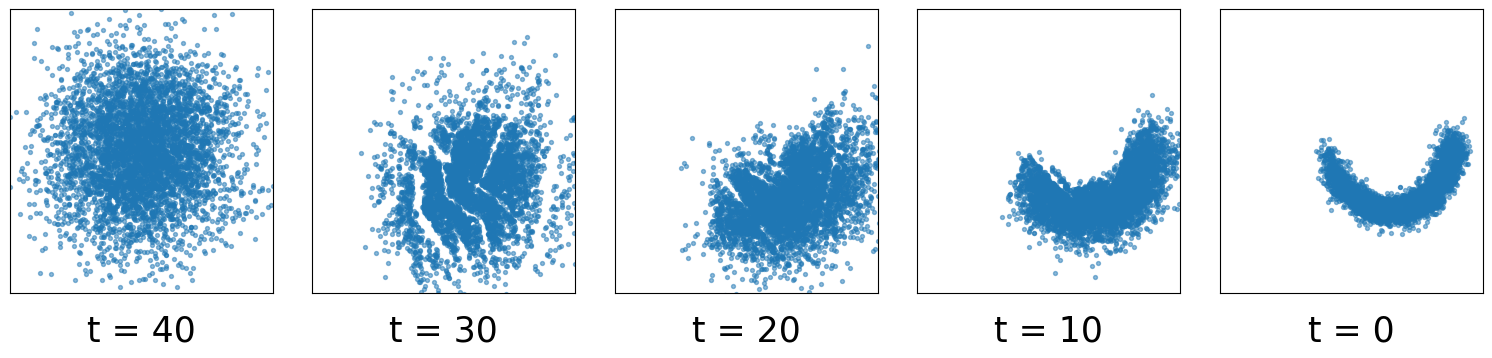

In [35]:
import matplotlib.pyplot as plt

n = len(xt_hist1)

fig, axes = plt.subplots(1, n, figsize=(3.8*n, 4.5))

if n == 1:
    axes = [axes]

for i, (ax, img) in enumerate(zip(axes, xt_hist1)):
    ax.scatter(img[:, 0], img[:, 1], s=8, alpha=0.5)

    ax.set_xlim(-3, 3)
    ax.set_ylim(-3, 3)

    ax.set_xticks([])
    ax.set_yticks([])

    ax.set_title(
        f"t = {[0, int(diffusion_steps/4), 2*int(diffusion_steps/4), int(3*diffusion_steps/4), diffusion_steps][::-1][i]}",
        y=-0.2,
        fontsize=25
    )

plt.subplots_adjust(wspace=0.15, bottom=0.25)
plt.show()

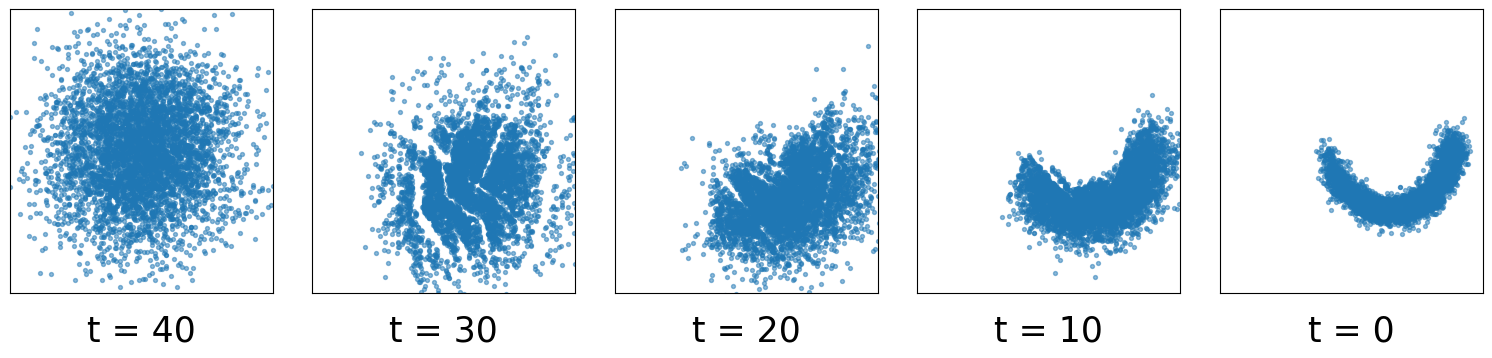

In [36]:
import matplotlib.pyplot as plt

n = len(xt_hist1)

fig, axes = plt.subplots(1, n, figsize=(3.8*n, 4.5))

if n == 1:
    axes = [axes]

for i, (ax, img) in enumerate(zip(axes, xt_hist1)):
    ax.scatter(img[:, 0], img[:, 1], s=8, alpha=0.5)

    ax.set_xlim(-3, 3)
    ax.set_ylim(-3, 3)

    ax.set_xticks([])
    ax.set_yticks([])

    ax.set_title(
        f"t = {[0, int(diffusion_steps/4), 2*int(diffusion_steps/4), int(3*diffusion_steps/4), diffusion_steps][::-1][i]}",
        y=-0.2,
        fontsize=25
    )

plt.subplots_adjust(wspace=0.15, bottom=0.25)
plt.show()

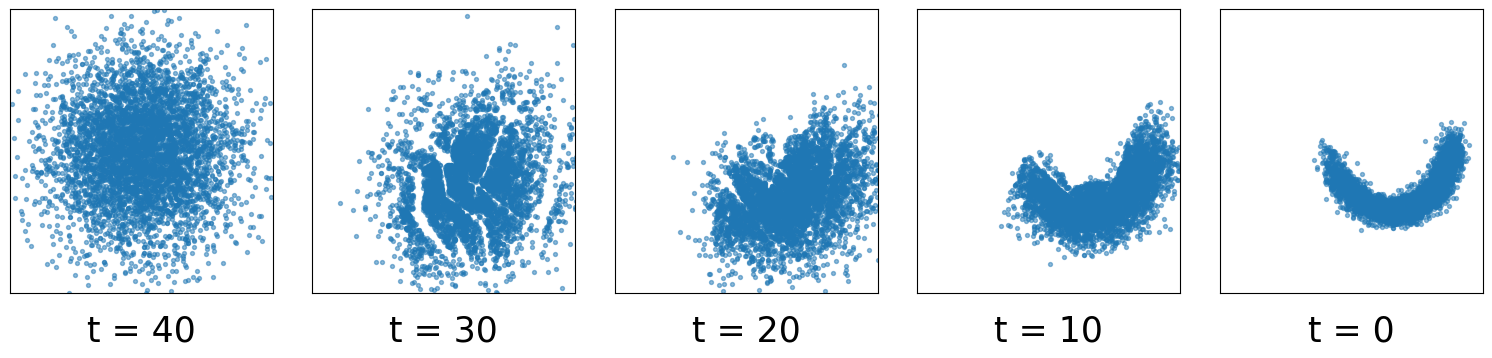

In [37]:
import matplotlib.pyplot as plt

n = len(xt_hist)

fig, axes = plt.subplots(1, n, figsize=(3.8*n, 4.5))

if n == 1:
    axes = [axes]

for i, (ax, img) in enumerate(zip(axes, xt_hist)):
    ax.scatter(img[:, 0], img[:, 1], s=8, alpha=0.5)

    ax.set_xlim(-3, 3)
    ax.set_ylim(-3, 3)

    ax.set_xticks([])
    ax.set_yticks([])

    ax.set_title(
        f"t = {[0, int(diffusion_steps/4), 2*int(diffusion_steps/4), int(3*diffusion_steps/4), diffusion_steps][::-1][i]}",
        y=-0.2,
        fontsize=25
    )

plt.subplots_adjust(wspace=0.15, bottom=0.25)
plt.show()